# Title : Data Wrangling on Real Estate Market

In [ ]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import warnings

In [ ]:
# Supressing update warnings
warnings.filterwarnings('ignore')

In [ ]:
df1 = pd.read_csv("/Bengaluru_House_Data.csv")

In [ ]:
df1.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [ ]:
df1.shape

(13320, 9)

In [ ]:
df1.columns

Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft', 'bath', 'balcony', 'price'],
      dtype='object')

In [ ]:
df1['area_type']

0        Super built-up  Area
1                  Plot  Area
2              Built-up  Area
3        Super built-up  Area
4        Super built-up  Area
                 ...         
13315          Built-up  Area
13316    Super built-up  Area
13317          Built-up  Area
13318    Super built-up  Area
13319    Super built-up  Area
Name: area_type, Length: 13320, dtype: object

In [ ]:
df1['area_type'].unique()

array(['Super built-up  Area', 'Plot  Area', 'Built-up  Area',
       'Carpet  Area'], dtype=object)

In [ ]:
df1['area_type'].value_counts()

Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: area_type, dtype: int64

In [ ]:
df2 = df1.drop(['area_type','society','balcony','availability'],axis='columns')

In [ ]:
df2.shape

(13320, 5)

In [ ]:
df2.isnull().sum()

location       1
size          16
total_sqft     0
bath          73
price          0
dtype: int64

In [ ]:
df2.shape

(13320, 5)

In [ ]:
df3 = df2.dropna()
df3.isnull().sum()

location      0
size          0
total_sqft    0
bath          0
price         0
dtype: int64

In [ ]:
df3.shape

(13246, 5)

In [ ]:
df3['size'].unique()

array(['2 BHK', '4 Bedroom', '3 BHK', '4 BHK', '6 Bedroom', '3 Bedroom',
       '1 BHK', '1 RK', '1 Bedroom', '8 Bedroom', '2 Bedroom',
       '7 Bedroom', '5 BHK', '7 BHK', '6 BHK', '5 Bedroom', '11 BHK',
       '9 BHK', '9 Bedroom', '27 BHK', '10 Bedroom', '11 Bedroom',
       '10 BHK', '19 BHK', '16 BHK', '43 Bedroom', '14 BHK', '8 BHK',
       '12 Bedroom', '13 BHK', '18 Bedroom'], dtype=object)

In [ ]:
df3['bhk'] = df3['size'].apply(lambda x: int(x.split(' ')[0]))

In [ ]:
df3.head()

,location,size,total_sqft,bath,price,bhk
0,Electronic City Phase II,2 BHK,1056,2.0,39.07,2
1,Chikka Tirupathi,4 Bedroom,2600,5.0,120.00,4
2,Uttarahalli,3 BHK,1440,2.0,62.00,3
3,Lingadheeranahalli,3 BHK,1521,3.0,95.00,3
4,Kothanur,2 BHK,1200,2.0,51.00,2


In [ ]:
df3.bhk.unique()

array([ 2,  4,  3,  6,  1,  8,  7,  5, 11,  9, 27, 10, 19, 16, 43, 14, 12,
       13, 18], dtype=int64)

In [ ]:
df3[df3.bhk>20]

,location,size,total_sqft,bath,price,bhk
1718,2Electronic City Phase II,27 BHK,8000,27.0,230.0,27
4684,Munnekollal,43 Bedroom,2400,40.0,660.0,43


In [ ]:
df3.total_sqft.unique()

array(['1056', '2600', '1440', ..., '1133 - 1384', '774', '4689'],
      dtype=object)

In [ ]:
def is_float(x):
    try:
        float(x)
        return True
    except(ValueError, TypeError):
        return False

In [ ]:
df3[~df3['total_sqft'].apply(is_float)].head(10)

,location,size,total_sqft,bath,price,bhk
30,Yelahanka,4 BHK,2100 - 2850,4.0,186.000,4
122,Hebbal,4 BHK,3067 - 8156,4.0,477.000,4
137,8th Phase JP Nagar,2 BHK,1042 - 1105,2.0,54.005,2
165,Sarjapur,2 BHK,1145 - 1340,2.0,43.490,2
188,KR Puram,2 BHK,1015 - 1540,2.0,56.800,2
410,Kengeri,1 BHK,34.46Sq. Meter,1.0,18.500,1
549,Hennur Road,2 BHK,1195 - 1440,2.0,63.770,2
648,Arekere,9 Bedroom,4125Perch,9.0,265.000,9
661,Yelahanka,2 BHK,1120 - 1145,2.0,48.130,2
672,Bettahalsoor,4 Bedroom,3090 - 5002,4.0,445.000,4


In [ ]:
def convert_sqft_to_num(x):
    tokens = x.split('-')
    if len(tokens) == 2:
        try:
            return (float(tokens[0])+float(tokens[1]))/2
        except ValueError:
            return None
    try:
        return float(x)
    except ValueError:
        return None

result = convert_sqft_to_num('2100 - 2850')
print(result)

2475.0


In [ ]:
convert_sqft_to_num('34.46Sq. Meter')
df4 = df3.copy()
df4.total_sqft = df4.total_sqft.apply(convert_sqft_to_num)
df4

,location,size,total_sqft,bath,price,bhk
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3
4,Kothanur,2 BHK,1200.0,2.0,51.00,2
...,...,...,...,...,...,...
13315,Whitefield,5 Bedroom,3453.0,4.0,231.00,5
13316,Richards Town,4 BHK,3600.0,5.0,400.00,4
13317,Raja Rajeshwari Nagar,2 BHK,1141.0,2.0,60.00,2
13318,Padmanabhanagar,4 BHK,4689.0,4.0,488.00,4


In [ ]:
df4 = df4[df4.total_sqft.notnull()]
df4

,location,size,total_sqft,bath,price,bhk
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3
4,Kothanur,2 BHK,1200.0,2.0,51.00,2
...,...,...,...,...,...,...
13315,Whitefield,5 Bedroom,3453.0,4.0,231.00,5
13316,Richards Town,4 BHK,3600.0,5.0,400.00,4
13317,Raja Rajeshwari Nagar,2 BHK,1141.0,2.0,60.00,2
13318,Padmanabhanagar,4 BHK,4689.0,4.0,488.00,4


In [ ]:
df4.loc[30]

location      Yelahanka
size              4 BHK
total_sqft       2475.0
bath                4.0
price             186.0
bhk                   4
Name: 30, dtype: object

In [ ]:
df5 = df4.copy()
df5['price_per_sqft'] = df5['price']*100000/df5['total_sqft']
df5.head()

,location,size,total_sqft,bath,price,bhk,price_per_sqft
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2,3699.810606
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4,4615.384615
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3,4305.555556
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3,6245.890861
4,Kothanur,2 BHK,1200.0,2.0,51.00,2,4250.000000


In [ ]:
df5_stats = df5['price_per_sqft'].describe()
df5_stats

count    1.320000e+04
mean     7.920759e+03
std      1.067272e+05
min      2.678298e+02
25%      4.267701e+03
50%      5.438331e+03
75%      7.317073e+03
max      1.200000e+07
Name: price_per_sqft, dtype: float64

In [ ]:
df5.to_csv("/bhp.csv",index=False)

In [ ]:
df5.location = df5.location.apply(lambda x: x.strip())
location_stats = df5['location'].value_counts(ascending=False)
location_stats

Whitefield                   533
Sarjapur  Road               392
Electronic City              304
Kanakpura Road               264
Thanisandra                  235
                            ... 
Rajanna Layout                 1
Subramanyanagar                1
Lakshmipura Vidyaanyapura      1
Malur Hosur Road               1
Abshot Layout                  1
Name: location, Length: 1287, dtype: int64

In [ ]:
len(location_stats[location_stats>10])

240

In [ ]:
len(location_stats)

1287

In [ ]:
len(location_stats[location_stats<=10])

1047

In [ ]:
location_stats_less_than_10 = location_stats[location_stats<=10]
location_stats_less_than_10

BTM 1st Stage                10
Gunjur Palya                 10
Nagappa Reddy Layout         10
Sector 1 HSR Layout          10
Thyagaraja Nagar             10
                             ..
Rajanna Layout                1
Subramanyanagar               1
Lakshmipura Vidyaanyapura     1
Malur Hosur Road              1
Abshot Layout                 1
Name: location, Length: 1047, dtype: int64

In [ ]:
len(df5.location.unique())

1287

In [ ]:
df5.location = df5.location.apply(lambda x: 'other' if x in location_stats_less_than_10 else x)
len(df5.location.unique())

241

In [ ]:
df5.head(10)

,location,size,total_sqft,bath,price,bhk,price_per_sqft
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2,3699.810606
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4,4615.384615
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3,4305.555556
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3,6245.890861
4,Kothanur,2 BHK,1200.0,2.0,51.00,2,4250.000000
5,Whitefield,2 BHK,1170.0,2.0,38.00,2,3247.863248
6,Old Airport Road,4 BHK,2732.0,4.0,204.00,4,7467.057101
7,Rajaji Nagar,4 BHK,3300.0,4.0,600.00,4,18181.818182
8,Marathahalli,3 BHK,1310.0,3.0,63.25,3,4828.244275
9,other,6 Bedroom,1020.0,6.0,370.00,6,36274.509804


In [ ]:
df5[df5.total_sqft/df5.bhk<300].head()

,location,size,total_sqft,bath,price,bhk,price_per_sqft
9,other,6 Bedroom,1020.0,6.0,370.0,6,36274.509804
45,HSR Layout,8 Bedroom,600.0,9.0,200.0,8,33333.333333
58,Murugeshpalya,6 Bedroom,1407.0,4.0,150.0,6,10660.980810
68,Devarachikkanahalli,8 Bedroom,1350.0,7.0,85.0,8,6296.296296
70,other,3 Bedroom,500.0,3.0,100.0,3,20000.000000


In [ ]:
df5.shape

(13200, 7)

In [ ]:
df6 = df5[~(df5.total_sqft/df5.bhk<300)]
df6.shape

(12456, 7)

In [ ]:
df6.columns

Index(['location', 'size', 'total_sqft', 'bath', 'price', 'bhk',
       'price_per_sqft'],
      dtype='object')

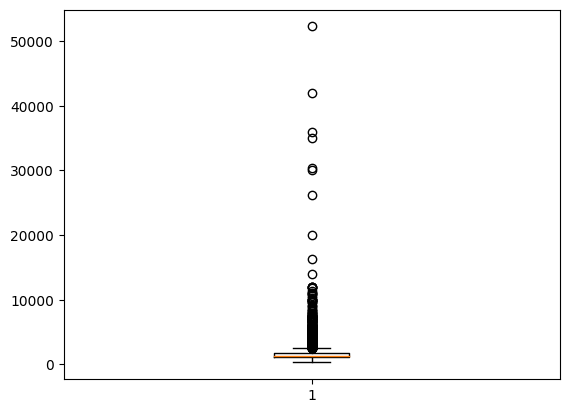

In [ ]:
plt.boxplot(df6['total_sqft'])
plt.show()

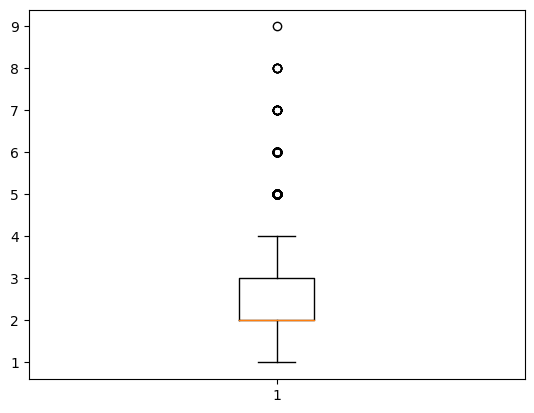

In [ ]:
Q1 = np.percentile(df6['total_sqft'], 25.) # 25th percentile of the data of the given feature
Q3 = np.percentile(df6['total_sqft'], 75.) # 75th percentile of the data of the given feature
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR)
ul = Q3 + (1.5*IQR)
upper_outliers = df6[df6['total_sqft'] > ul].index.tolist()
lower_outliers = df6[df6['total_sqft'] < ll].index.tolist()
bad_indices = list(set(upper_outliers + lower_outliers))
drop = True
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')

plt.boxplot(df6['bath'])
plt.show()

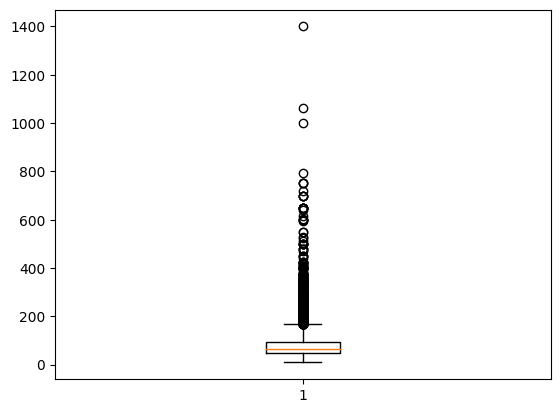

In [ ]:
Q1 = np.percentile(df6['bath'], 25.) # 25th percentile of the data of the given feature
Q3 = np.percentile(df6['bath'], 75.) # 75th percentile of the data of the given feature
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR)
ul = Q3 + (1.5*IQR)
upper_outliers = df6[df6['bath'] > ul].index.tolist()
lower_outliers = df6[df6['bath'] < ll].index.tolist()
bad_indices = list(set(upper_outliers + lower_outliers))
drop = True
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')
plt.boxplot(df6['price'])
plt.show()

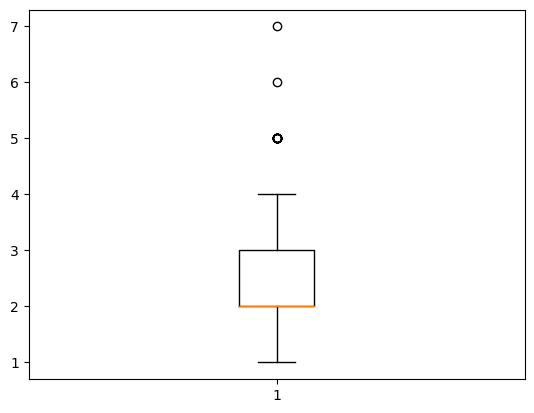

In [ ]:
Q1 = np.percentile(df6['price'], 25.) # 25th percentile of the data of the given feature
Q3 = np.percentile(df6['price'], 75.) # 75th percentile of the data of the given feature
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR)
ul = Q3 + (1.5*IQR)

upper_outliers = df6[df6['price'] > ul].index.tolist()
lower_outliers = df6[df6['price'] < ll].index.tolist()
bad_indices = list(set(upper_outliers + lower_outliers))
drop = True
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')

plt.boxplot(df6['bhk'])
plt.show()

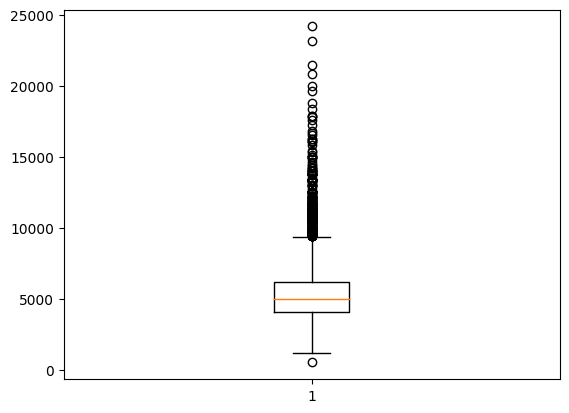

In [ ]:
Q1 = np.percentile(df6['bhk'], 25.) # 25th percentile of the data of the given feature
Q3 = np.percentile(df6['bhk'], 75.) # 75th percentile of the data of the given feature
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR)
ul = Q3 + (1.5*IQR)
upper_outliers = df6[df6['bhk'] > ul].index.tolist()
lower_outliers = df6[df6['bhk'] < ll].index.tolist()
bad_indices = list(set(upper_outliers + lower_outliers))
drop = True
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')

plt.boxplot(df6['price_per_sqft'])
plt.show()

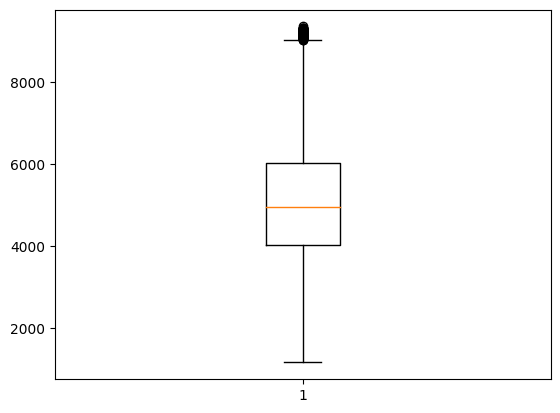

In [ ]:
Q1 = np.percentile(df6['bhk'], 25.) # 25th percentile of the data of the given feature
Q3 = np.percentile(df6['bhk'], 75.) # 75th percentile of the data of the given feature
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR)
ul = Q3 + (1.5*IQR)
upper_outliers = df6[df6['bhk'] > ul].index.tolist()
lower_outliers = df6[df6['bhk'] < ll].index.tolist()
bad_indices = list(set(upper_outliers + lower_outliers))
drop = True
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')

plt.boxplot(df6['price_per_sqft'])
plt.show()

In [ ]:
df6.shape

(10090, 7)

In [ ]:
X = df6.drop(['price'],axis='columns')
X.head(3)

,location,size,total_sqft,bath,bhk,price_per_sqft
0,Electronic City Phase II,2 BHK,1056.0,2.0,2,3699.810606
2,Uttarahalli,3 BHK,1440.0,2.0,3,4305.555556
3,Lingadheeranahalli,3 BHK,1521.0,3.0,3,6245.890861


In [ ]:
X.shape

(10090, 6)

In [ ]:
y = df6.price
y.head(3)

0    39.07
2    62.00
3    95.00
Name: price, dtype: float64

In [ ]:
len(y)

10090

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=10)

X_train.shape

(8072, 6)

In [ ]:
y_train.shape

(8072,)

In [ ]:
X_test.shape

(2018, 6)

In [ ]:
y_test.shape

(2018,)

In [ ]:

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import warnings
# Supressing update warnings
warnings.filterwarnings('ignore')
df1 = pd.read_csv("/Bengaluru_House_Data.csv")
df1.head()
df1.shape
df1['area_type']
df1['area_type'].unique()
df1['area_type'].value_counts()
df2 = df1.drop(['area_type','society','balcony','availability'],axis='columns')
df2.shape
df2.isnull().sum()
df2.shape
df3 = df2.dropna()
df3.isnull().sum()
df3.shape
df3['size'].unique()
df3['bhk'] = df3['size'].apply(lambda x: int(x.split(' ')[0]))
df3.head()
df3.bhk.unique()
df3[df3.bhk>20]
df3.total_sqft.unique()
def is_float(x):
    try:
        float(x)
        return True
    except(ValueError, TypeError):
        return False
df3[~df3['total_sqft'].apply(is_float)].head(10)
def convert_sqft_to_num(x):
    tokens = x.split('-')
    if len(tokens) == 2:
        try:
            return (float(tokens[0])+float(tokens[1]))/2
        except ValueError:
            return None
    try:
        return float(x)
    except ValueError:
        return None

result = convert_sqft_to_num('2100 - 2850')
print(result)
convert_sqft_to_num('34.46Sq. Meter')
df4 = df3.copy()
df4.total_sqft = df4.total_sqft.apply(convert_sqft_to_num)
df4
df4 = df4[df4.total_sqft.notnull()]
df4
df4.loc[30]
df5 = df4.copy()
df5['price_per_sqft'] = df5['price']*100000/df5['total_sqft']
df5.head()
df5_stats = df5['price_per_sqft'].describe()
df5_stats
df5.to_csv("/bhp.csv",index=False)
df5.location = df5.location.apply(lambda x: x.strip())
location_stats = df5['location'].value_counts(ascending=False)
location_stats
len(location_stats[location_stats>10])
len(location_stats)
len(location_stats[location_stats<=10])
location_stats_less_than_10 = location_stats[location_stats<=10]
location_stats_less_than_10
len(df5.location.unique())
df5.location = df5.location.apply(lambda x: 'other' if x in location_stats_less_than_10 else x)
len(df5.location.unique())
df5.head(10)
df5[df5.total_sqft/df5.bhk<300].head()
df5.shape
df6 = df5[~(df5.total_sqft/df5.bhk<300)]
df6.shape
df6.columns
plt.boxplot(df6['total_sqft'])
plt.show()
Q1 = np.percentile(df6['total_sqft'], 25.) # 25th percentile of the data of the given feature
Q3 = np.percentile(df6['total_sqft'], 75.) # 75th percentile of the data of the given feature
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR)
ul = Q3 + (1.5*IQR)
upper_outliers = df6[df6['total_sqft'] > ul].index.tolist()
lower_outliers = df6[df6['total_sqft'] < ll].index.tolist()
bad_indices = list(set(upper_outliers + lower_outliers))
drop = True
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')

plt.boxplot(df6['bath'])
plt.show()
Q1 = np.percentile(df6['bath'], 25.) # 25th percentile of the data of the given feature
Q3 = np.percentile(df6['bath'], 75.) # 75th percentile of the data of the given feature
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR)
ul = Q3 + (1.5*IQR)
upper_outliers = df6[df6['bath'] > ul].index.tolist()
lower_outliers = df6[df6['bath'] < ll].index.tolist()
bad_indices = list(set(upper_outliers + lower_outliers))
drop = True
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')
plt.boxplot(df6['price'])
plt.show()
Q1 = np.percentile(df6['price'], 25.) # 25th percentile of the data of the given feature
Q3 = np.percentile(df6['price'], 75.) # 75th percentile of the data of the given feature
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR)
ul = Q3 + (1.5*IQR)

upper_outliers = df6[df6['price'] > ul].index.tolist()
lower_outliers = df6[df6['price'] < ll].index.tolist()
bad_indices = list(set(upper_outliers + lower_outliers))
drop = True
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')

plt.boxplot(df6['bhk'])
plt.show()
Q1 = np.percentile(df6['bhk'], 25.) # 25th percentile of the data of the given feature
Q3 = np.percentile(df6['bhk'], 75.) # 75th percentile of the data of the given feature
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR)
ul = Q3 + (1.5*IQR)
upper_outliers = df6[df6['bhk'] > ul].index.tolist()
lower_outliers = df6[df6['bhk'] < ll].index.tolist()
bad_indices = list(set(upper_outliers + lower_outliers))
drop = True
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')

plt.boxplot(df6['price_per_sqft'])
plt.show()
Q1 = np.percentile(df6['bhk'], 25.) # 25th percentile of the data of the given feature
Q3 = np.percentile(df6['bhk'], 75.) # 75th percentile of the data of the given feature
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR)
ul = Q3 + (1.5*IQR)
upper_outliers = df6[df6['bhk'] > ul].index.tolist()
lower_outliers = df6[df6['bhk'] < ll].index.tolist()
bad_indices = list(set(upper_outliers + lower_outliers))
drop = True
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')

plt.boxplot(df6['price_per_sqft'])
plt.show()
df6.shape
X = df6.drop(['price'],axis='columns')
X.head(3)
X.shape
y = df6.price
y.head(3)
len(y)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=10)

X_train.shape
y_train.shape
X_test.shape
y_test.shape


*italicized text*

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import warnings

warnings.filterwarnings('ignore')

# Import dataset
df1 = pd.read_csv("/Bengaluru_House_Data.csv")

# Clean column names
df1.columns = (df1.columns
               .str.strip()
               .str.lower()
               .str.replace(r'[^a-z0-9]+', '_', regex=True)
               .str.strip('_'))

df1.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [2]:
df1.shape
df1.info()
df1.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [3]:
df1['area_type']
df1['area_type'].unique()
df1['area_type'].value_counts()

,count
area_type,
Super built-up Area,8790
Built-up Area,2418
Plot Area,2025
Carpet Area,87


In [4]:
df2 = df1.drop(
    ['society', 'balcony', 'availability'],
    axis='columns',
    errors='ignore'
)

df2.shape
df2.isnull().sum()

,0
area_type,0
location,1
size,16
total_sqft,0
bath,73
price,0


In [5]:
missing_percentage = (df2.isnull().sum() / len(df2)) * 100

print(missing_percentage.sort_values(ascending=False))

bath          0.548048
size          0.120120
location      0.007508
area_type     0.000000
total_sqft    0.000000
price         0.000000
dtype: float64


In [6]:
df3 = df2.dropna().copy()

df3.isnull().sum()
df3.shape

(13246, 6)

In [7]:
df3['size'].unique()

df3['bhk'] = df3['size'].apply(
    lambda x: int(x.split(' ')[0])
)

df3.head()

df3.bhk.unique()

df3[df3.bhk > 20]

,area_type,location,size,total_sqft,bath,price,bhk
1718,Super built-up Area,2Electronic City Phase II,27 BHK,8000,27.0,230.0,27
4684,Plot Area,Munnekollal,43 Bedroom,2400,40.0,660.0,43


In [8]:
def convert_sqft_to_num(x):

    if pd.isna(x):
        return None

    x = str(x).strip()

    # Handle square meters
    if 'Sq. Meter' in x:
        return float(x.replace('Sq. Meter', '').strip()) * 10.7639

    # Handle square yards
    if 'Sq. Yards' in x:
        return float(x.replace('Sq. Yards', '').strip()) * 9

    # Handle ranges
    tokens = x.split('-')

    if len(tokens) == 2:
        try:
            return (float(tokens[0]) + float(tokens[1])) / 2
        except ValueError:
            return None

    # Handle normal numeric values
    try:
        return float(x)
    except ValueError:
        return None

In [9]:
convert_sqft_to_num('2100 - 2850')

convert_sqft_to_num('34.46Sq. Meter')

370.923994

In [10]:
df4 = df3.copy()

df4['total_sqft'] = df4['total_sqft'].apply(
    convert_sqft_to_num
)

df4 = df4[df4.total_sqft.notnull()].copy()

df4.head()

df4.shape

(13232, 7)

In [11]:
df5 = df4.copy()

df5['price_per_sqft'] = (
    df5['price'] * 100000 / df5['total_sqft']
)

df5.head()

,area_type,location,size,total_sqft,bath,price,bhk,price_per_sqft
0,Super built-up Area,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2,3699.810606
1,Plot Area,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4,4615.384615
2,Built-up Area,Uttarahalli,3 BHK,1440.0,2.0,62.00,3,4305.555556
3,Super built-up Area,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3,6245.890861
4,Super built-up Area,Kothanur,2 BHK,1200.0,2.0,51.00,2,4250.000000


In [12]:
df5_stats = df5['price_per_sqft'].describe()

df5_stats

,price_per_sqft
count,1.323200e+04
mean,7.922795e+03
std,1.066013e+05
min,2.678298e+02
25%,4.265734e+03
50%,5.437935e+03
75%,7.323336e+03
max,1.200000e+07


In [13]:
df5.to_csv("bhp.csv", index=False)

In [14]:
df5.location = df5.location.apply(lambda x: x.strip())

location_stats = df5['location'].value_counts(
    ascending=False
)

location_stats

,count
location,
Whitefield,535
Sarjapur Road,392
Electronic City,304
Kanakpura Road,264
Thanisandra,236
...,...
Raja Rajashweri Nagar,1
mvj engineering college,1
akshaya nagar t c palya,1


In [15]:
len(location_stats[location_stats > 10])

len(location_stats)

len(location_stats[location_stats <= 10])

1048

In [16]:
location_stats_less_than_10 = location_stats[
    location_stats <= 10
]

df5.location = df5.location.apply(
    lambda x: 'other'
    if x in location_stats_less_than_10
    else x
)

len(df5.location.unique())

df5.head(10)

,area_type,location,size,total_sqft,bath,price,bhk,price_per_sqft
0,Super built-up Area,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2,3699.810606
1,Plot Area,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4,4615.384615
2,Built-up Area,Uttarahalli,3 BHK,1440.0,2.0,62.00,3,4305.555556
3,Super built-up Area,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3,6245.890861
4,Super built-up Area,Kothanur,2 BHK,1200.0,2.0,51.00,2,4250.000000
5,Super built-up Area,Whitefield,2 BHK,1170.0,2.0,38.00,2,3247.863248
6,Super built-up Area,Old Airport Road,4 BHK,2732.0,4.0,204.00,4,7467.057101
7,Super built-up Area,Rajaji Nagar,4 BHK,3300.0,4.0,600.00,4,18181.818182
8,Super built-up Area,Marathahalli,3 BHK,1310.0,3.0,63.25,3,4828.244275
9,Plot Area,other,6 Bedroom,1020.0,6.0,370.00,6,36274.509804


In [17]:
# Filter properties based on location

location_data = df5[
    df5['location'] == 'other'
]

location_data.head()

,area_type,location,size,total_sqft,bath,price,bhk,price_per_sqft
9,Plot Area,other,6 Bedroom,1020.0,6.0,370.0,6,36274.509804
18,Super built-up Area,other,3 BHK,2770.0,4.0,290.0,3,10469.314079
19,Super built-up Area,other,2 BHK,1100.0,2.0,48.0,2,4363.636364
25,Super built-up Area,other,3 BHK,1250.0,3.0,56.0,3,4480.000000
42,Super built-up Area,other,1 BHK,600.0,1.0,38.0,1,6333.333333


In [18]:
# Properties having 2 or 3 BHK

filtered_data = df5[
    df5['bhk'].isin([2, 3])
]

filtered_data.head()

,area_type,location,size,total_sqft,bath,price,bhk,price_per_sqft
0,Super built-up Area,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2,3699.810606
2,Built-up Area,Uttarahalli,3 BHK,1440.0,2.0,62.00,3,4305.555556
3,Super built-up Area,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3,6245.890861
4,Super built-up Area,Kothanur,2 BHK,1200.0,2.0,51.00,2,4250.000000
5,Super built-up Area,Whitefield,2 BHK,1170.0,2.0,38.00,2,3247.863248


In [19]:
# Average house price by location

location_summary = df5.groupby('location').agg(
    average_price=('price', 'mean'),
    minimum_price=('price', 'min'),
    maximum_price=('price', 'max'),
    average_sqft=('total_sqft', 'mean'),
    property_count=('price', 'count')
).reset_index()

location_summary.head(10)

,location,average_price,minimum_price,maximum_price,average_sqft,property_count
0,1st Block Jayanagar,207.500000,50.0,450.0,1691.428571,14
1,1st Phase JP Nagar,170.700000,50.0,400.0,1738.236285,25
2,2nd Phase Judicial Layout,46.181818,26.0,69.0,1173.272727,11
3,2nd Stage Nagarbhavi,220.833333,82.0,451.0,1410.416667,24
4,5th Block Hbr Layout,202.750000,48.0,675.0,1849.000000,12
5,5th Phase JP Nagar,86.112821,23.5,290.0,1368.230769,39
6,6th Phase JP Nagar,105.386957,48.9,250.0,1364.391304,23
7,7th Phase JP Nagar,100.522953,38.0,450.0,1479.328859,149
8,8th Phase JP Nagar,77.975351,29.9,270.0,1280.385965,57
9,9th Phase JP Nagar,89.583721,20.0,300.0,1393.331395,43


In [20]:
# Average house price by area type

property_summary = df5.groupby('area_type').agg(
    average_price=('price', 'mean'),
    average_sqft=('total_sqft', 'mean'),
    property_count=('price', 'count')
).reset_index()

property_summary

,area_type,average_price,average_sqft,property_count
0,Built-up Area,103.921615,1641.744719,2409
1,Carpet Area,89.502356,1295.648119,87
2,Plot Area,209.619795,1852.789900,1996
3,Super built-up Area,92.641922,1480.105325,8740


In [21]:
location_price_summary = df5.groupby('location')[
    'price_per_sqft'
].mean().reset_index()

location_price_summary.columns = [
    'location',
    'average_price_per_sqft'
]

location_price_summary.head(10)

,location,average_price_per_sqft
0,1st Block Jayanagar,11496.236323
1,1st Phase JP Nagar,10048.326621
2,2nd Phase Judicial Layout,4048.701183
3,2nd Stage Nagarbhavi,17349.228395
4,5th Block Hbr Layout,12137.476027
5,5th Phase JP Nagar,6578.681949
6,6th Phase JP Nagar,8356.779524
7,7th Phase JP Nagar,6596.232221
8,8th Phase JP Nagar,6385.019507
9,9th Phase JP Nagar,6803.438951


In [22]:
df5[df5.total_sqft / df5.bhk < 300].head()

df5.shape

df6 = df5[
    ~(df5.total_sqft / df5.bhk < 300)
].copy()

df6.shape

(12485, 8)

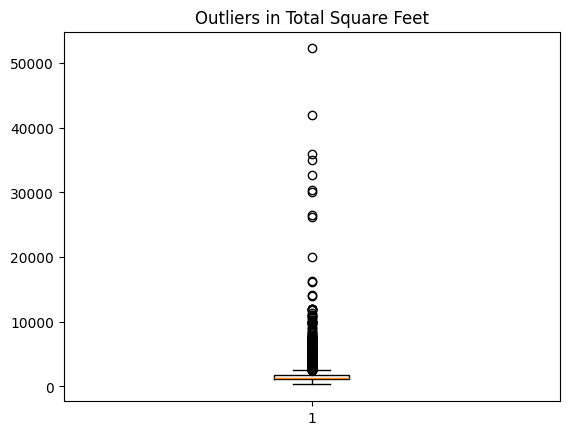

In [23]:
plt.boxplot(df6['total_sqft'])
plt.title('Outliers in Total Square Feet')
plt.show()

In [24]:
def remove_outliers_iqr(data, column):

    Q1 = np.percentile(data[column], 25)
    Q3 = np.percentile(data[column], 75)

    IQR = Q3 - Q1

    ll = Q1 - (1.5 * IQR)
    ul = Q3 + (1.5 * IQR)

    return data[
        (data[column] >= ll) &
        (data[column] <= ul)
    ].copy()

In [25]:
# Remove outliers

df6 = remove_outliers_iqr(df6, 'total_sqft')

df6 = remove_outliers_iqr(df6, 'bath')

df6 = remove_outliers_iqr(df6, 'price')

df6 = remove_outliers_iqr(df6, 'bhk')

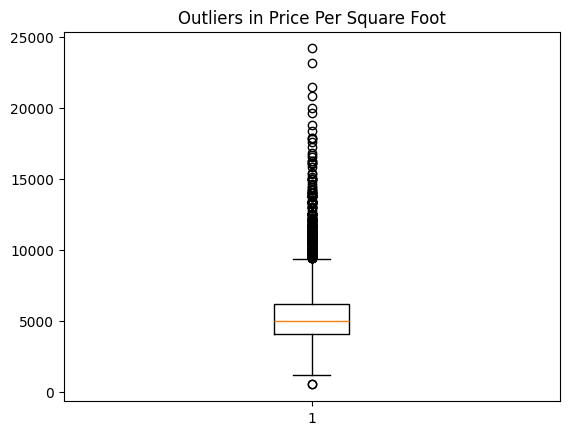

In [26]:
plt.boxplot(df6['price_per_sqft'])

plt.title('Outliers in Price Per Square Foot')

plt.show()

# Correct IQR calculation

Q1 = np.percentile(df6['price_per_sqft'], 25)

Q3 = np.percentile(df6['price_per_sqft'], 75)

IQR = Q3 - Q1

ll = Q1 - (1.5 * IQR)

ul = Q3 + (1.5 * IQR)

upper_outliers = df6[
    df6['price_per_sqft'] > ul
].index.tolist()

lower_outliers = df6[
    df6['price_per_sqft'] < ll
].index.tolist()

bad_indices = list(
    set(upper_outliers + lower_outliers)
)

df6 = df6.drop(
    bad_indices,
    errors='ignore'
).copy()

In [27]:
df6.shape

df6.head()

,area_type,location,size,total_sqft,bath,price,bhk,price_per_sqft
0,Super built-up Area,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2,3699.810606
2,Built-up Area,Uttarahalli,3 BHK,1440.0,2.0,62.00,3,4305.555556
3,Super built-up Area,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3,6245.890861
4,Super built-up Area,Kothanur,2 BHK,1200.0,2.0,51.00,2,4250.000000
5,Super built-up Area,Whitefield,2 BHK,1170.0,2.0,38.00,2,3247.863248


In [28]:
# Separate independent and dependent variables

X = df6.drop(['price'], axis='columns')

y = df6.price

X.head(3)

X.shape

y.head(3)

len(y)

10102

In [29]:
# Identify categorical columns

categorical_columns = X.select_dtypes(
    include=['object', 'category']
).columns

print(categorical_columns)

Index(['area_type', 'location', 'size'], dtype='object')


In [30]:
# One-hot encoding

X = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

X.head()

X.shape

(10102, 253)

In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=10
)

X_train.shape

y_train.shape

X_test.shape

y_test.shape

(8081, 253)